# Library

In [1]:
%pip install -q tiktoken

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3
import tiktoken

# Dtype

In [3]:
data = pd.read_csv("imdb_top_1000.csv")

In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 16 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Poster_Link    1000 non-null   object 
 1   Series_Title   1000 non-null   object 
 2   Released_Year  1000 non-null   object 
 3   Certificate    899 non-null    object 
 4   Runtime        1000 non-null   object 
 5   Genre          1000 non-null   object 
 6   IMDB_Rating    1000 non-null   float64
 7   Overview       1000 non-null   object 
 8   Meta_score     843 non-null    float64
 9   Director       1000 non-null   object 
 10  Star1          1000 non-null   object 
 11  Star2          1000 non-null   object 
 12  Star3          1000 non-null   object 
 13  Star4          1000 non-null   object 
 14  No_of_Votes    1000 non-null   int64  
 15  Gross          831 non-null    object 
dtypes: float64(2), int64(1), object(13)
memory usage: 125.1+ KB


In [5]:
data.head(2)

,Poster_Link,Series_Title,Released_Year,Certificate,Runtime,Genre,IMDB_Rating,Overview,Meta_score,Director,Star1,Star2,Star3,Star4,No_of_Votes,Gross
0,https://m.media-amazon.com/images/M/MV5BMDFkYT...,The Shawshank Redemption,1994,A,142 min,Drama,9.3,Two imprisoned men bond over a number of years...,80.0,Frank Darabont,Tim Robbins,Morgan Freeman,Bob Gunton,William Sadler,2343110,"28,341,469"
1,https://m.media-amazon.com/images/M/MV5BM2MyNj...,The Godfather,1972,A,175 min,"Crime, Drama",9.2,An organized crime dynasty's aging patriarch t...,100.0,Francis Ford Coppola,Marlon Brando,Al Pacino,James Caan,Diane Keaton,1620367,"134,966,411"


# Data Cleaning & EDA

In [6]:
unique_counts = data.nunique()
print("Jumlah nilai unik di setiap kolom:")
display(unique_counts)

Jumlah nilai unik di setiap kolom:


Poster_Link      1000
Series_Title      999
Released_Year     100
Certificate        16
Runtime           140
Genre             202
IMDB_Rating        17
Overview         1000
Meta_score         63
Director          548
Star1             660
Star2             841
Star3             891
Star4             939
No_of_Votes       999
Gross             823
dtype: int64

C:\Users\h y p e\AppData\Local\Temp\ipykernel_17796\2160809029.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=data, x='Certificate', order=data['Certificate'].value_counts().index, palette='viridis')


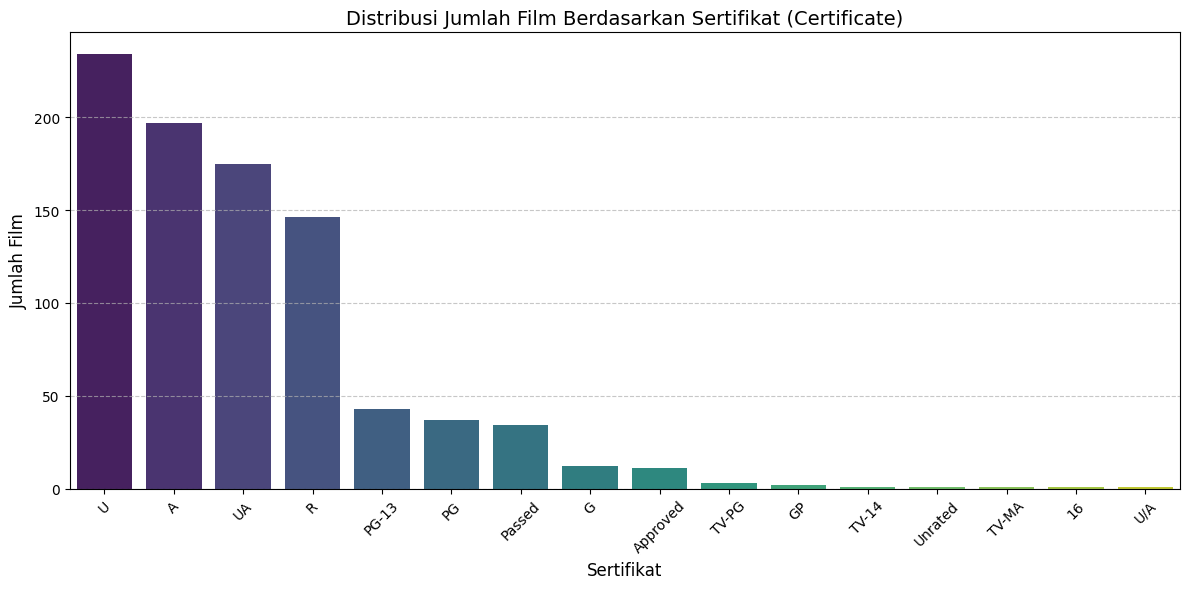

In [7]:
# Mengatur ukuran figure
plt.figure(figsize=(12, 6))

# Membuat bar chart untuk kolom Certificate
sns.countplot(data=data, x='Certificate', order=data['Certificate'].value_counts().index, palette='viridis')

# Menambahkan judul dan label
plt.title('Distribusi Jumlah Film Berdasarkan Sertifikat (Certificate)', fontsize=14)
plt.xlabel('Sertifikat', fontsize=12)
plt.ylabel('Jumlah Film', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Menampilkan plot
plt.tight_layout()
plt.show()

### Penjelasan Sertifikat Rating Film

Sertifikat rating film dalam dataset ini umumnya mengikuti sistem klasifikasi sensor film (terutama sistem sensor India - CBFC, atau sistem Inggris/internasional lainnya yang sering muncul di IMDb):

1. **U (Unrestricted Public Exhibition)**:
   * **Arti:** Semua Umur.
   * **Penjelasan:** Film dengan sertifikasi ini aman ditonton oleh semua kelompok usia, termasuk anak-anak. Kontennya ramah keluarga.

2. **UA (Unrestricted Public Exhibition with Parental Guidance)**:
   * **Arti:** Bimbingan Orang Tua untuk anak di bawah 12 tahun.
   * **Penjelasan:** Film aman ditonton secara umum, namun disarankan ada bimbingan atau pendampingan orang tua bagi penonton anak-anak karena mungkin mengandung elemen yang sedikit lebih dewasa.

3. **A (Adult)**:
   * **Arti:** Dewasa (18+).
   * **Penjelasan:** Hanya untuk penonton yang telah berusia 18 tahun ke atas. Film ini biasanya mengandung konten kekerasan, bahasa kasar, atau tema dewasa yang tidak cocok untuk anak-anak.

4. **R (Restricted)**:
   * **Arti:** Terbatas (Sistem MPA Amerika Serikat).
   * **Penjelasan:** Penonton di bawah 17 tahun membutuhkan pendampingan dari orang tua atau wali dewasa karena kontennya yang cukup intens.

5. **PG-13 / PG (Parental Guidance)**:
   * **Arti:** Bimbingan Orang Tua.
   * **Penjelasan:** Beberapa materi mungkin tidak cocok untuk anak-anak. Khusus PG-13, orang tua sangat diperingatkan karena ada konten yang kurang sesuai untuk anak di bawah 13 tahun.

6. **Passed / Approved / G**:
   * **Arti:** Lolos sensor zaman dulu / Umum.
   * **Penjelasan:** Biasanya digunakan untuk film klasik yang dirilis sebelum sistem rating modern dibuat, menandakan film tersebut lolos sensor dan aman ditonton umum.

In [8]:
# 1. Konversi Released_Year ke numerik (menghilangkan baris non-angka jika ada)
data['Released_Year_numeric'] = pd.to_numeric(data['Released_Year'], errors='coerce')

# 2. Konversi Runtime (menghilangkan kata 'min' dan mengubah menjadi integer)
data['Runtime_minutes'] = data['Runtime'].str.replace(' min', '').astype(float)

# Menampilkan sampel data setelah pembersihan
display(data[['Released_Year', 'Released_Year_numeric', 'Runtime', 'Runtime_minutes']].head(3))

,Released_Year,Released_Year_numeric,Runtime,Runtime_minutes
0,1994,1994.0,142 min,142.0
1,1972,1972.0,175 min,175.0
2,2008,2008.0,152 min,152.0


In [9]:
# Membersihkan kolom Gross menjadi numerik
data['Gross_cleaned'] = (
    data['Gross']
    .astype('string')
    .str.replace(r'[$,]', '', regex=True)
    .replace({'': pd.NA, '-': pd.NA, 'nan': pd.NA})
)

data['Gross_cleaned'] = pd.to_numeric(
    data['Gross_cleaned'],
    errors='coerce'
)

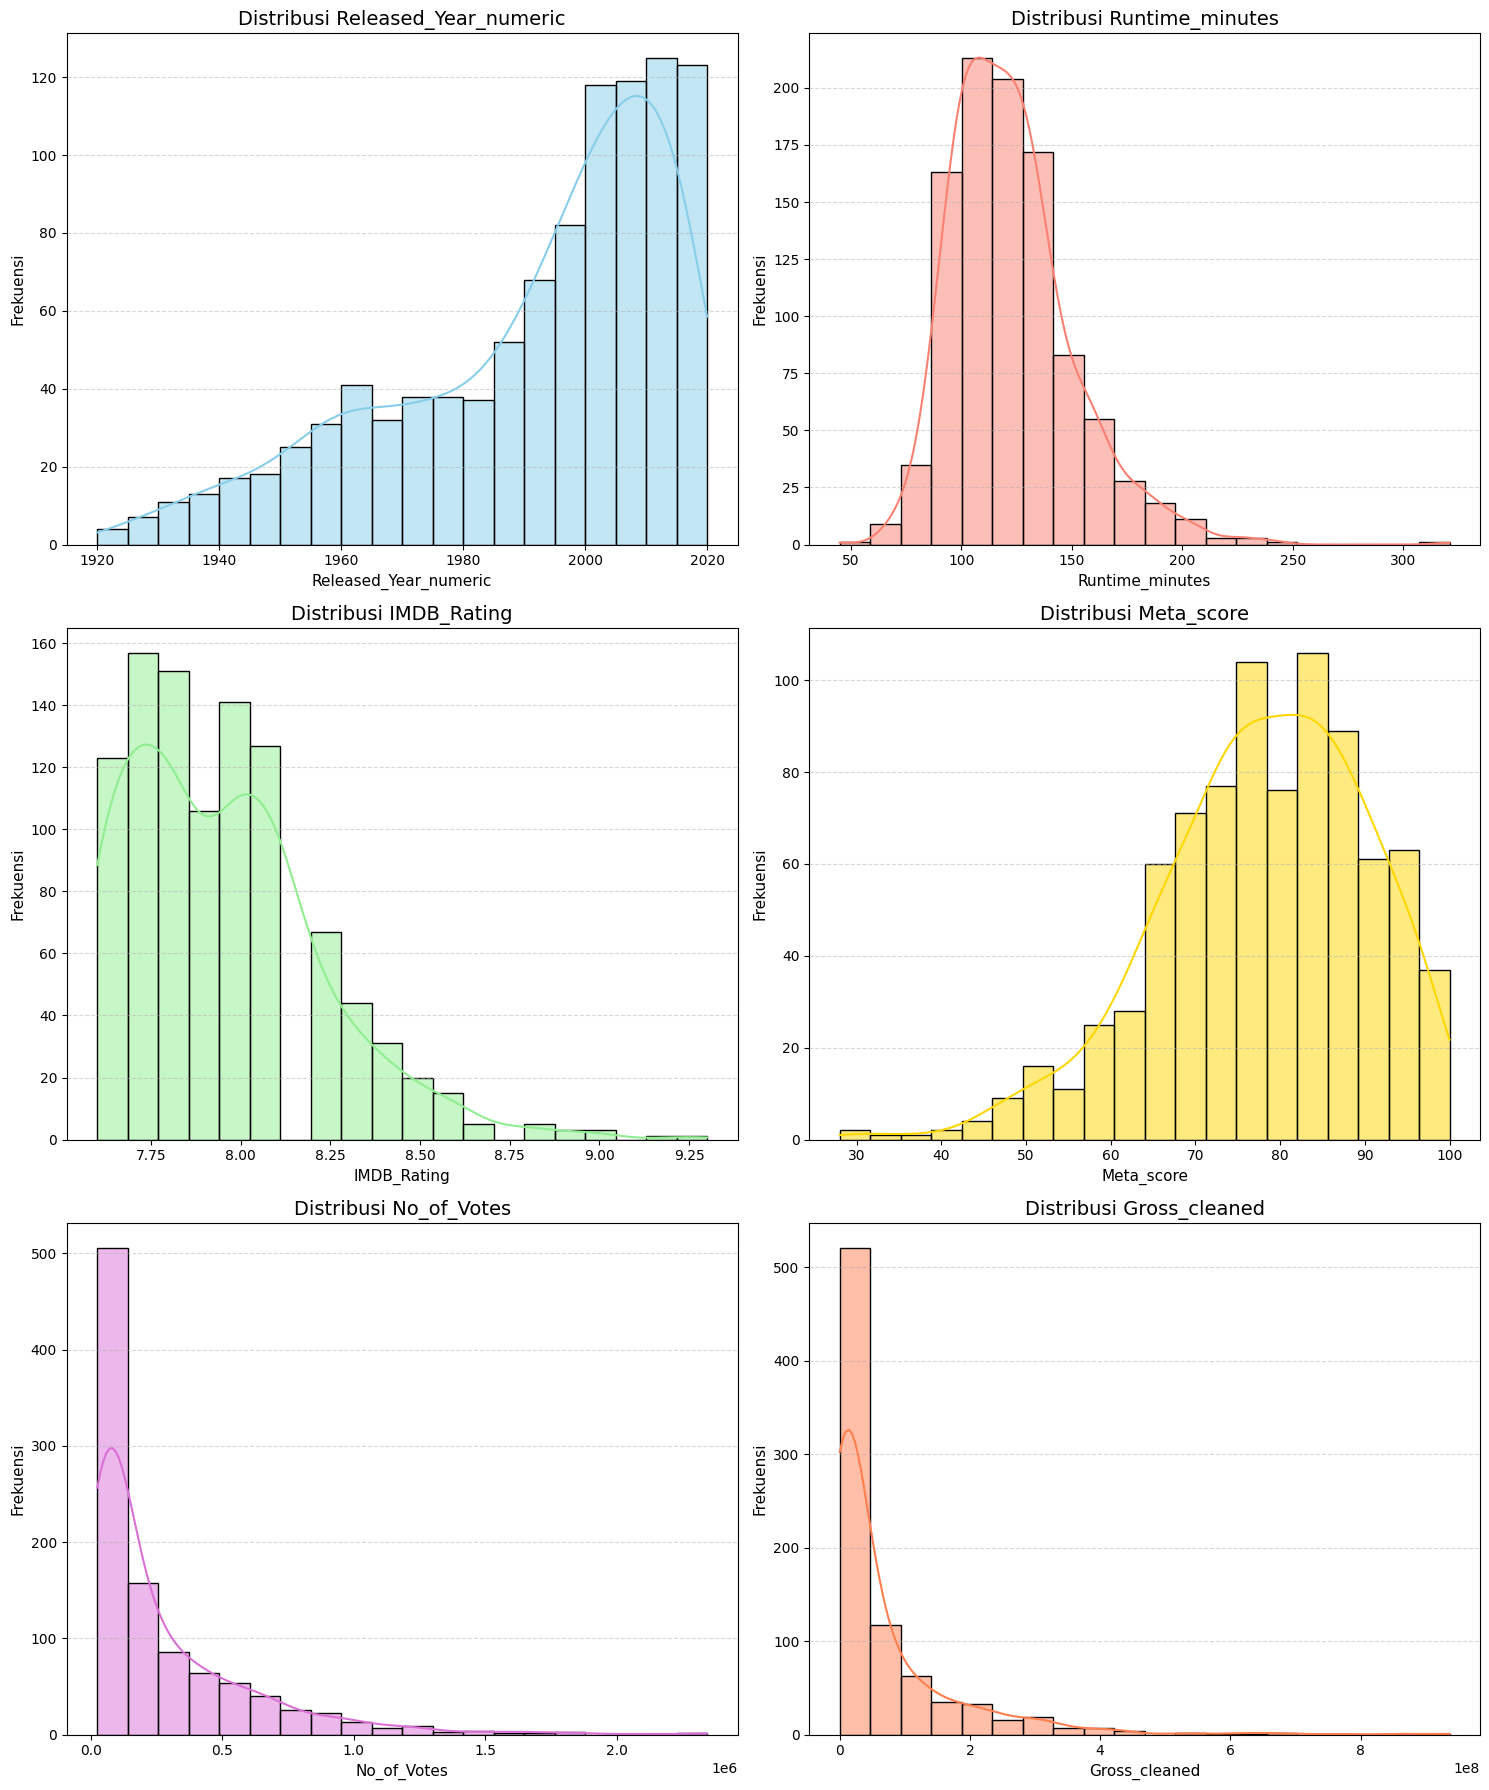

In [10]:
# Menentukan kolom numerik yang akan di-plot
numeric_cols = ['Released_Year_numeric', 'Runtime_minutes', 'IMDB_Rating', 'Meta_score', 'No_of_Votes', 'Gross_cleaned']
colors = ['skyblue', 'salmon', 'lightgreen', 'gold', 'orchid', 'coral']

# Membuat subplots grid 3x2
fig, axes = plt.subplots(3, 2, figsize=(15, 18))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    sns.histplot(data=data, x=col, kde=True, ax=axes[i], color=colors[i], bins=20)
    axes[i].set_title(f'Distribusi {col}', fontsize=14)
    axes[i].set_xlabel(col, fontsize=11)
    axes[i].set_ylabel('Frekuensi', fontsize=11)
    axes[i].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [11]:
columns_to_drop = ['Runtime', 'Released_Year', 'Gross']
clean_data = data.drop(columns=[col for col in columns_to_drop if col in data.columns])


# norm

In [12]:
string_cols = clean_data.select_dtypes(include=['object']).columns
for col in string_cols:
    clean_data[col] = clean_data[col].astype(str).str.lower()


In [13]:
clean_data.head(1)

,Poster_Link,Series_Title,Certificate,Genre,IMDB_Rating,Overview,Meta_score,Director,Star1,Star2,Star3,Star4,No_of_Votes,Released_Year_numeric,Runtime_minutes,Gross_cleaned
0,https://m.media-amazon.com/images/m/mv5bmdfkyt...,the shawshank redemption,a,drama,9.3,two imprisoned men bond over a number of years...,80.0,frank darabont,tim robbins,morgan freeman,bob gunton,william sadler,2343110,1994.0,142.0,28341469


# Ingest

### Format

In [14]:
conn = sqlite3.connect("database.db")
cursor = conn.cursor()

# 1. Menghapus SEMUA baris data di dalam tabel (Tabel tetap ada, data hilang)
cursor.execute("DELETE FROM imdb_movies")

# 2. Opsional: Reset nomor ID (AUTOINCREMENT) agar kembali mulai dari 1 lagi
cursor.execute("DELETE FROM sqlite_sequence WHERE name='imdb_movies'")

conn.commit()
conn.close()

print("Seluruh isi data tabel 'imdb_movies' berhasil dihapus!")

Seluruh isi data tabel 'imdb_movies' berhasil dihapus!


### SQLite

In [15]:
# 1. Buka koneksi ke database SQLite
conn = sqlite3.connect("database.db")
cursor = conn.cursor()

# 2. Buat tabel dengan Primary Key (id) dan seluruh kolom data Anda
cursor.execute("""
    CREATE TABLE IF NOT EXISTS imdb_movies (
        id INTEGER PRIMARY KEY AUTOINCREMENT,
        Poster_Link TEXT,
        Series_Title TEXT,
        Certificate TEXT,
        Genre TEXT,
        IMDB_Rating REAL,
        Overview TEXT,
        Meta_score REAL,
        Director TEXT,
        Star1 TEXT,
        Star2 TEXT,
        Star3 TEXT,
        Star4 TEXT,
        No_of_Votes INTEGER,
        Released_Year_numeric REAL,
        Runtime_minutes REAL,
        Gross_cleaned REAL
    )
""")

# 3. Masukkan data Pandas ke tabel SQLite
clean_data.to_sql("imdb_movies", conn, if_exists="append", index=False)

# 4. Simpan perubahan dan tutup koneksi
conn.commit()
conn.close()

print("Berhasil! Tabel 'imdb_movies' dibuat dengan Primary Key 'id' dan data dimasukkan.")

Berhasil! Tabel 'imdb_movies' dibuat dengan Primary Key 'id' dan data dimasukkan.


### Qdrant

In [16]:
# 1. Buka koneksi ke database SQLite
conn = sqlite3.connect("database.db")

# 2. Ambil data dari tabel imdb_movies (diurutkan berdasarkan id)
query = """
SELECT id, Series_Title, Genre, Overview, Director, Star1, Star2, Star3, Star4 
FROM imdb_movies 
ORDER BY id ASC
"""
df_raw = pd.read_sql_query(query, conn)

# 3. Tutup koneksi
conn.close()


# 4. Fungsi untuk memformat baris data menjadi teks tunggal yang kaya konteks
def format_embedding_text(row):
    stars = ", ".join(
        [
            str(row[col])
            for col in ["Star1", "Star2", "Star3", "Star4"]
            if pd.notna(row[col])
        ]
    )
    return (
        f"Title: {row['Series_Title']}\n"
        f"Genre: {row['Genre']}\n"
        f"Director: {row['Director']}\n"
        f"Cast: {stars}\n"
        f"Overview: {row['Overview']}"
    )


# 5. Buat DataFrame baru berisi 2 kolom (id & text_to_embed)
df_result = pd.DataFrame()
df_result["id"] = df_raw["id"]
df_result["text_to_embed"] = df_raw.apply(format_embedding_text, axis=1)


In [17]:
df_result

,id,text_to_embed
0,1,Title: the shawshank redemption\nGenre: drama\...
1,2,"Title: the godfather\nGenre: crime, drama\nDir..."
2,3,"Title: the dark knight\nGenre: action, crime, ..."
3,4,"Title: the godfather: part ii\nGenre: crime, d..."
4,5,"Title: 12 angry men\nGenre: crime, drama\nDire..."
...,...,...
995,996,"Title: breakfast at tiffany's\nGenre: comedy, ..."
996,997,"Title: giant\nGenre: drama, western\nDirector:..."
997,998,"Title: from here to eternity\nGenre: drama, ro..."
998,999,"Title: lifeboat\nGenre: drama, war\nDirector: ..."


=== DISTRIBUSI TOKEN OVERVIEW SAJA ===


count    1000.000000
mean       78.114000
std        11.466319
min        52.000000
25%        70.000000
50%        77.000000
75%        85.000000
max       119.000000
Name: tokens_overview_only, dtype: float64

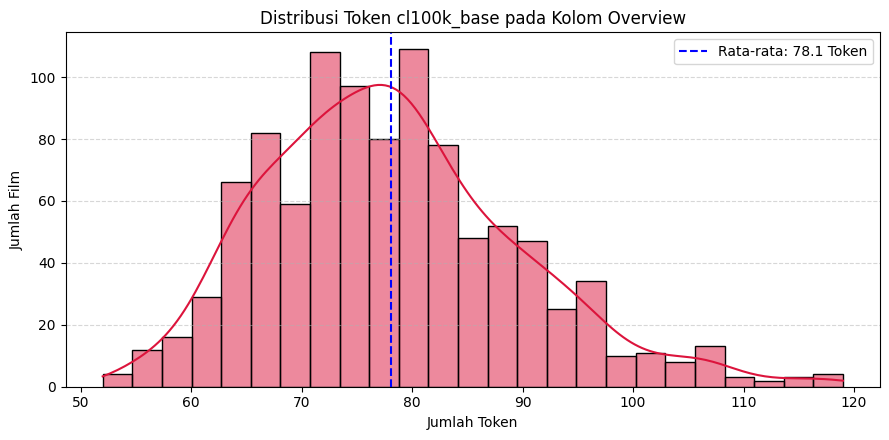

In [18]:
# 1. Menggunakan encoder standar cl100k_base
encoding = tiktoken.get_encoding("cl100k_base")

# 2. Fungsi sederhana menghitung token untuk kolom Overview
data['tokens_overview_only'] = df_result['text_to_embed'].fillna('').apply(lambda x: len(encoding.encode(str(x))))

# 3. Tampilkan statistik deskriptif sederhana
print("=== DISTRIBUSI TOKEN OVERVIEW SAJA ===")
display(data['tokens_overview_only'].describe())

# 4. Plot distribusi
plt.figure(figsize=(9, 4.5))
sns.histplot(data=data, x='tokens_overview_only', kde=True, color='crimson', bins=25)
plt.axvline(data['tokens_overview_only'].mean(), color='blue', linestyle='--', label=f"Rata-rata: {data['tokens_overview_only'].mean():.1f} Token")
plt.title('Distribusi Token cl100k_base pada Kolom Overview', fontsize=12)
plt.xlabel('Jumlah Token')
plt.ylabel('Jumlah Film')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [19]:
from pathlib import Path
import os
from dotenv import load_dotenv
from openai import OpenAI
from qdrant_client import QdrantClient
from qdrant_client.models import Distance, PointStruct, VectorParams

# 1. Load file .env langsung dari path src/imdb_anwar/.env
env_path = Path("../src/imdb_anwar/.env")
load_dotenv(dotenv_path=env_path)

OPENROUTER_API_KEY = os.getenv("OPENROUTER_API_KEY")
EMBED_MODEL = os.getenv("Embed_MODEL")
QDRANT_HOST = os.getenv("Qdrant_HOST")
QDRANT_API = os.getenv("Qdrant_API")

# Validasi API Key
if not OPENROUTER_API_KEY:
    raise ValueError(
        f"OPENROUTER_API_KEY tidak ditemukan di {env_path.resolve()}"
    )

In [20]:

# 2. Inisialisasi OpenRouter Client
client = OpenAI(
    base_url="https://openrouter.ai/api/v1", api_key=OPENROUTER_API_KEY
)

# 3. Batch Generate Embedding untuk df_result['Overview']
print("Membuat embedding via OpenRouter...")
res = client.embeddings.create(
    model=EMBED_MODEL, input=df_result["text_to_embed"].tolist()
)
df_result["embed"] = [item.embedding for item in res.data]


Membuat embedding via OpenRouter...


In [21]:
df_result = df_result.drop(columns=["text_to_embed"])

In [22]:
df_result

,id,embed
0,1,"[-0.032867431640625, 0.0066070556640625, -0.01..."
1,2,"[-0.046600341796875, 0.0458984375, -0.08984375..."
2,3,"[-0.034027099609375, 0.023284912109375, -0.028..."
3,4,"[-0.056488037109375, 0.021148681640625, -0.065..."
4,5,"[-0.00942230224609375, 0.050628662109375, -0.0..."
...,...,...
995,996,"[-0.06719970703125, 0.009063720703125, -0.0455..."
996,997,"[-0.032470703125, 0.003902435302734375, -0.012..."
997,998,"[-0.05047607421875, 0.056060791015625, 0.00191..."
998,999,"[-0.070556640625, 0.031280517578125, 0.0100402..."


In [23]:
# 4. Simpan ke File Lokal Staging (Parquet) di folder data/
parquet_path = Path("staging_imdb.parquet")  # Menyimpan langsung di folder data/
df_result.to_parquet(parquet_path, index=False)
print(f"Staging Parquet berhasil disimpan di: {parquet_path.resolve()}")

Staging Parquet berhasil disimpan di: C:\Users\h y p e\Desktop\Capstone_Manual\IMDB_Anwar\data\staging_imdb.parquet


In [24]:
# 5. Connect ke Qdrant Remote/Cloud (Tambahkan timeout 60 detik)
qdrant = QdrantClient(url=QDRANT_HOST, api_key=QDRANT_API, timeout=60.0)

COLLECTION_NAME = "imdb_movies"

if not qdrant.collection_exists(COLLECTION_NAME):
    qdrant.create_collection(
        collection_name=COLLECTION_NAME,
        vectors_config=VectorParams(size=1536, distance=Distance.COSINE),
    )

# 6. Push Poin ke Qdrant (Secara Bertahap / Batching)
df_staging = pd.read_parquet(parquet_path)
points = [
    PointStruct(
        id=int(row["id"]),
        vector=row["embed"],
        payload={"sqlite_id": int(row["id"])},
    )
    for _, row in df_staging.iterrows()
]

print("Mengunggah data ke Qdrant Cloud secara bertahap...")
batch_size_qdrant = 100

for i in range(0, len(points), batch_size_qdrant):
    batch_points = points[i : i + batch_size_qdrant]
    qdrant.upsert(collection_name=COLLECTION_NAME, points=batch_points)
    print(
        f"Upsert Qdrant batch {i // batch_size_qdrant + 1}/{(len(points) - 1) // batch_size_qdrant + 1} berhasil."
    )

print(
    f"Selesai! Berhasil memasukkan total {len(points)} vektor ke Qdrant Cloud!"
)

Mengunggah data ke Qdrant Cloud secara bertahap...
Upsert Qdrant batch 1/10 berhasil.
Upsert Qdrant batch 2/10 berhasil.
Upsert Qdrant batch 3/10 berhasil.
Upsert Qdrant batch 4/10 berhasil.
Upsert Qdrant batch 5/10 berhasil.
Upsert Qdrant batch 6/10 berhasil.
Upsert Qdrant batch 7/10 berhasil.
Upsert Qdrant batch 8/10 berhasil.
Upsert Qdrant batch 9/10 berhasil.
Upsert Qdrant batch 10/10 berhasil.
Selesai! Berhasil memasukkan total 1000 vektor ke Qdrant Cloud!


In [25]:
# Cek info umum collection
collection_info = qdrant.get_collection("imdb_movies")

print(f"Status Collection : {collection_info.status}")
print(f"Total Vektor Masuk: {collection_info.points_count}")
print(f"Dimensi Vektor    : {collection_info.config.params.vectors.size}")

Status Collection : green
Total Vektor Masuk: 1000
Dimensi Vektor    : 1536


In [26]:
# Query contoh untuk tes pencarian
query_text = "film perselisihan rumah tangga (horror)"

# 1. Generate embedding untuk query menggunakan OpenRouter
query_vector = (
    client.embeddings.create(model=EMBED_MODEL, input=query_text)
    .data[0]
    .embedding
)

# 2. Cari 3 dokumen paling mirip di Qdrant
search_result = qdrant.query_points(
    collection_name="imdb_movies", query=query_vector, limit=3
).points

# 3. Tampilkan hasil
print(f"=== HASIL PENCARIAN SEMANTIK UTK: '{query_text}' ===\n")
for hit in search_result:
    print(f"Score Kemiripan : {hit.score:.4f}")
    print(f"SQLite ID       : {hit.payload.get('sqlite_id')}")
    print("-" * 60)

=== HASIL PENCARIAN SEMANTIK UTK: 'film perselisihan rumah tangga (horror)' ===

Score Kemiripan : 0.4471
SQLite ID       : 901
------------------------------------------------------------
Score Kemiripan : 0.4367
SQLite ID       : 338
------------------------------------------------------------
Score Kemiripan : 0.4245
SQLite ID       : 204
------------------------------------------------------------
